# Which movie recommender works best? Five approaches on MovieLens

A common first recommender takes a movie, finds the movies whose ratings correlate most with it, and recommends those. This notebook measures how well that works against four alternatives, on the question a recommender is actually asked: **given what someone has rated so far, which ten movies should they see next?**

Data: MovieLens `ml-latest-small` from GroupLens, 100,836 ratings of 9,742 movies by 610 users (1996 to 2018). It is downloaded on first run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from recommender.data import Interactions, load, split_by_time
from recommender.metrics import evaluate
from recommender.models import (EASE, ItemCosine, ItemPearson, Popularity, PureSVD,
                                pearson_similarity, similar_items)

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

ratings, movies = load("data")
title = movies.set_index("movieId")["title"]
print(f"{len(ratings):,} ratings, {ratings.userId.nunique()} users, {ratings.movieId.nunique():,} movies")
print(f"Ratings per user: median {ratings.groupby('userId').size().median():.0f}, "
      f"minimum {ratings.groupby('userId').size().min()}")
print(f"Share of the user-movie matrix filled: {len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique()):.1%}")

100,836 ratings, 610 users, 9,724 movies
Ratings per user: median 70, minimum 20
Share of the user-movie matrix filled: 1.7%


The most-rated 10% of movies receive 60% of all ratings; 62% of movies have fewer than five.


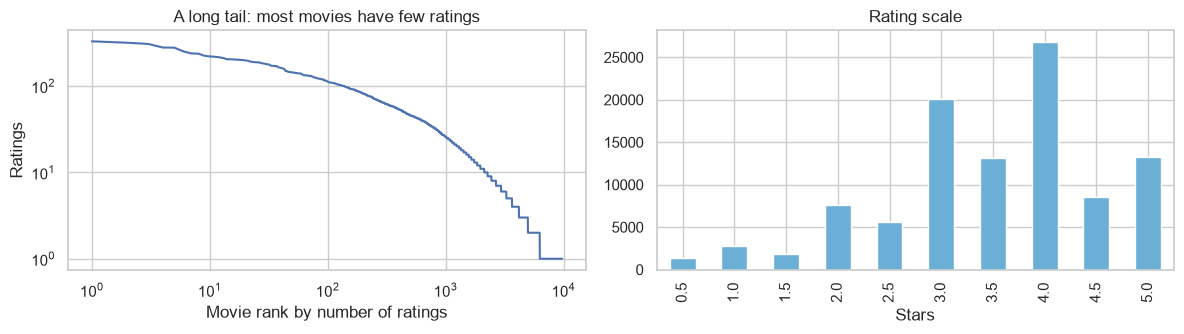

In [2]:
per_movie = ratings.groupby("movieId").size().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(np.arange(1, len(per_movie) + 1), per_movie.to_numpy())
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Movie rank by number of ratings"); axes[0].set_ylabel("Ratings")
axes[0].set_title("A long tail: most movies have few ratings")
ratings["rating"].value_counts().sort_index().plot.bar(ax=axes[1], color="#6baed6")
axes[1].set_title("Rating scale"); axes[1].set_xlabel("Stars")
plt.tight_layout()
share_top = per_movie.iloc[: int(len(per_movie) * 0.1)].sum() / len(ratings)
print(f"The most-rated 10% of movies receive {share_top:.0%} of all ratings; "
      f"{(per_movie < 5).mean():.0%} of movies have fewer than five.")

## 1. The evaluation

For every user, the **latest 20%** of their ratings are held out. Each model sees the earlier 80% and recommends ten movies the user has not yet rated. A recommendation counts as a hit if the user later rated that movie **4 stars or more**.

A time-based split is harder than a random one, because tastes drift and the model cannot learn from a user's later ratings. It is closer to how a recommender is used.

Metrics, all at ten recommendations:

- **precision**: share of the ten that were hits
- **recall**: share of the user's later liked movies that were found (out of at most ten)
- **NDCG**: like recall, but a hit counts for more near the top of the list
- **catalogue coverage**: share of all movies that get recommended to anyone

Settings for each model are tuned on a second time split inside the training data, so the test set is used only once.

In [3]:
train, test = split_by_time(ratings)
fit_part, validation = split_by_time(train)

tune_data = Interactions.from_frame(fit_part)
tune_relevant = tune_data.relevant(validation)

candidates = {
    "PureSVD": [PureSVD(k) for k in (10, 20, 30, 50, 100)],
    "EASE": [EASE(l2) for l2 in (30, 100, 300, 1000, 3000)],
    "Item-item Pearson": [ItemPearson(m) for m in (3, 5, 10, 25, 50)],
}
setting = {"PureSVD": "factors", "EASE": "l2", "Item-item Pearson": "min_common"}
tuning, best = [], {}
for name, models in candidates.items():
    for model in models:
        result = evaluate(model.fit(tune_data), tune_data, tune_relevant)
        tuning.append({"model": name, "setting": getattr(model, setting[name]), **result})
    rows = pd.DataFrame(tuning).query("model == @name")
    best[name] = rows.loc[rows["ndcg@10"].idxmax(), "setting"]
tuning = pd.DataFrame(tuning)
tuning.round(3)

,model,setting,precision@10,recall@10,ndcg@10,catalogue coverage,ratings per recommended movie
0,PureSVD,10,0.083,0.138,0.116,0.047,140.204
1,PureSVD,20,0.083,0.137,0.119,0.062,127.657
2,PureSVD,30,0.078,0.129,0.113,0.075,121.370
3,PureSVD,50,0.072,0.123,0.105,0.085,111.971
4,PureSVD,100,0.062,0.111,0.091,0.108,95.861
5,EASE,30,0.073,0.120,0.104,0.095,110.887
6,EASE,100,0.077,0.131,0.112,0.084,118.986
7,EASE,300,0.079,0.135,0.115,0.072,128.758
8,EASE,1000,0.077,0.135,0.114,0.055,143.336
9,EASE,3000,0.073,0.125,0.110,0.038,159.325


In [4]:
print("Chosen on validation:", best)

Chosen on validation: {'PureSVD': np.int64(20), 'EASE': np.int64(300), 'Item-item Pearson': np.int64(50)}


## 2. Results on the held-out ratings

In [5]:
data = Interactions.from_frame(train)
relevant = data.relevant(test)
print(f"{len(relevant)} users have at least one later movie they rated 4 stars or more")

models = {
    "Most popular": Popularity(),
    "Item-item cosine": ItemCosine(),
    "Item-item Pearson, 10 shared raters": ItemPearson(10),
    "Item-item Pearson, tuned": ItemPearson(int(best["Item-item Pearson"])),
    "PureSVD": PureSVD(int(best["PureSVD"])),
    "EASE": EASE(best["EASE"]),
}
results = pd.DataFrame({name: evaluate(m.fit(data), data, relevant) for name, m in models.items()}).T
results.round(3)

590 users have at least one later movie they rated 4 stars or more


,precision@10,recall@10,ndcg@10,catalogue coverage,ratings per recommended movie
Most popular,0.056,0.074,0.074,0.012,216.753
Item-item cosine,0.056,0.083,0.073,0.057,115.832
"Item-item Pearson, 10 shared raters",0.042,0.052,0.051,0.069,74.957
"Item-item Pearson, tuned",0.072,0.096,0.091,0.021,166.672
PureSVD,0.083,0.120,0.106,0.061,140.101
EASE,0.082,0.117,0.102,0.067,140.824


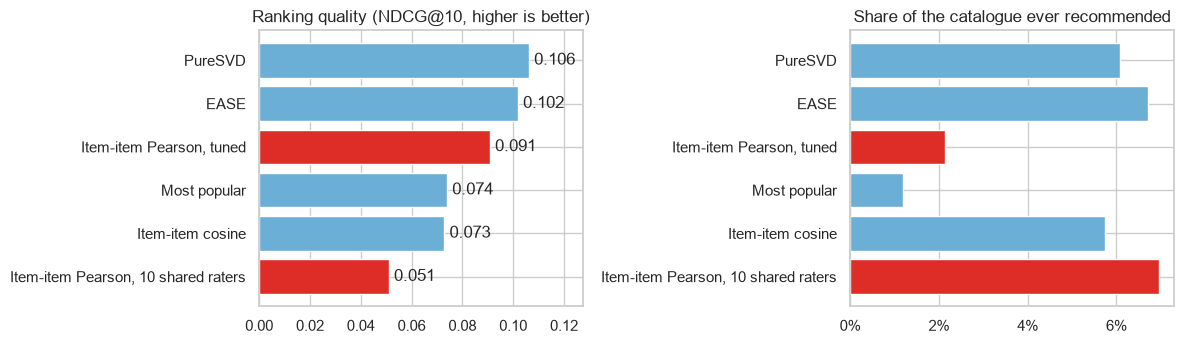

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
order = results.sort_values("ndcg@10").index
colours = ["#de2d26" if n.startswith("Item-item Pearson") else "#6baed6" for n in order]
axes[0].barh(order, results.loc[order, "ndcg@10"], color=colours)
for i, v in enumerate(results.loc[order, "ndcg@10"]):
    axes[0].text(v + 0.002, i, f"{v:.3f}", va="center")
axes[0].set_title("Ranking quality (NDCG@10, higher is better)")
axes[0].set_xlim(0, results["ndcg@10"].max() * 1.2)
axes[1].barh(order, results.loc[order, "catalogue coverage"], color=colours)
axes[1].set_title("Share of the catalogue ever recommended")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.savefig("images/results.png", dpi=150)

In [7]:
lift = results["ndcg@10"] / results.loc["Most popular", "ndcg@10"] - 1
lift.rename("NDCG compared with recommending the most popular movies").map("{:+.0%}".format).to_frame()

,NDCG compared with recommending the most popular movies
Most popular,+0%
Item-item cosine,-1%
"Item-item Pearson, 10 shared raters",-31%
"Item-item Pearson, tuned",+23%
PureSVD,+44%
EASE,+38%


- **The two linear models win clearly.** PureSVD and EASE rank the movies people go on to like about 40% better than a list of the most popular movies.
- **Correlation, built the usual way, loses to popularity.** Requiring 10 shared raters per pair, a common choice, scores below the popularity list. Tuned to 50 shared raters it beats popularity by about a fifth, but only by recommending blockbusters: it covers 2% of the catalogue.
- **Popularity is a hard baseline.** It recommends barely 1% of the catalogue, yet item-item cosine, which uses each user's own history, only ties it.

## 3. Why correlation does badly

A correlation between two movies is computed over the people who rated both. For most pairs that is only a few people, and a correlation from three people is often a perfect 1 by chance. The `min_common` threshold sets how many shared raters a pair needs before its correlation counts. The tuning table already shows how much depends on it:

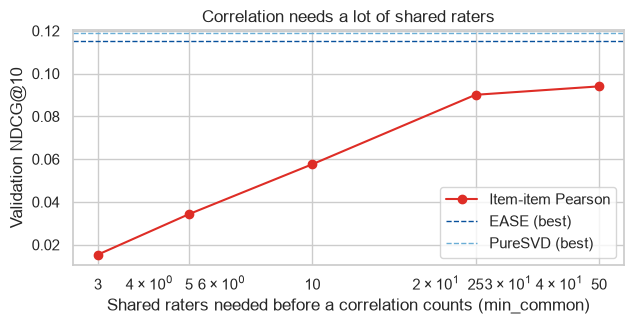

In [8]:
pearson = tuning.query("model == 'Item-item Pearson'")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(pearson["setting"], pearson["ndcg@10"], marker="o", color="#de2d26", label="Item-item Pearson")
for name, colour in [("EASE", "#08519c"), ("PureSVD", "#6baed6")]:
    ax.axhline(tuning.query("model == @name")["ndcg@10"].max(), color=colour, ls="--", lw=1, label=f"{name} (best)")
ax.set_xscale("log")
ax.set_xticks(pearson["setting"]); ax.set_xticklabels(pearson["setting"])
ax.set_xlabel("Shared raters needed before a correlation counts (min_common)")
ax.set_ylabel("Validation NDCG@10")
ax.set_title("Correlation needs a lot of shared raters")
ax.legend()
plt.tight_layout()
plt.savefig("images/pearson_threshold.png", dpi=150)

With a low threshold the recommendations are dominated by obscure movies that happen to correlate perfectly. Raising it helps, but throws away every movie with few ratings, and it still falls short of the linear models.

The effect is easy to see on a single title. These are the movies most similar to *The Matrix* under each approach, with the number of ratings each has in the training data:

In [9]:
count = pd.Series(np.asarray(data.seen.sum(axis=0)).ravel().astype(int), index=data.items)
column = {movie: i for i, movie in enumerate(data.items)}
dense = data.ratings.toarray()
similarities = {
    "Pearson, 3 shared raters": pearson_similarity(dense, min_common=3),
    "Pearson, 50 shared raters": pearson_similarity(dense, min_common=50),
    "Cosine": models["Item-item cosine"].similarity,
    "EASE": models["EASE"].weights.T,
}

def neighbours(movie_id, n=8):
    table = {}
    for name, sim in similarities.items():
        idx = similar_items(sim, column[movie_id], n)
        table[name] = [f"{title[data.items[i]][:34]} ({count.iloc[i]})" for i in idx]
    return pd.DataFrame(table, index=range(1, n + 1))

matrix = movies.loc[movies.title.str.startswith("Matrix, The"), "movieId"].iloc[0]
with pd.option_context("display.max_colwidth", 45):
    display(neighbours(matrix))

,"Pearson, 3 shared raters","Pearson, 50 shared raters",Cosine,EASE
1,Nebraska (2013) (3),Star Wars: Episode III - Revenge o (65),Fight Club (1999) (198),Star Wars: Episode IV - A New Hope (237)
2,Spartan (2004) (3),Die Hard (1988) (126),Star Wars: Episode V - The Empire (193),Fight Club (1999) (198)
3,"Interpreter, The (2005) (4)",Aliens (1986) (106),Star Wars: Episode IV - A New Hope (237),Star Wars: Episode V - The Empire (193)
4,"Shipping News, The (2001) (3)",300 (2007) (66),Saving Private Ryan (1998) (174),Saving Private Ryan (1998) (174)
5,Louis C.K.: Live at the Beacon The (3),"Lion King, The (1994) (157)",Lord of the Rings: The Fellowship (185),"Sixth Sense, The (1999) (160)"
6,Following (1998) (5),Rain Man (1988) (88),"Sixth Sense, The (1999) (160)",Raiders of the Lost Ark (Indiana J (177)
7,Citizen Ruth (1996) (4),"Matrix Reloaded, The (2003) (82)",Lord of the Rings: The Return of t (175),Inception (2010) (125)
8,"Thousand Words, A (2012) (3)",Braveheart (1995) (226),Star Wars: Episode VI - Return of (177),Lord of the Rings: The Return of t (175)


With only three shared raters required, *The Matrix* is "most similar" to movies that three to five people have rated: chance agreement, not taste. With fifty, the list is sensible, but every candidate must have been rated by at least fifty people, which rules out most of the catalogue. Cosine and EASE give fitting neighbours (science fiction, action, the films the same audience watched) without needing a threshold.

## 4. Who gets good recommendations?

Accuracy is broken down by how many movies each user had rated before the split.

In [10]:
history = pd.Series(np.asarray(data.seen.sum(axis=1)).ravel())
groups = pd.qcut(history, 4, labels=["fewest", "fewer", "more", "most"])
by_history = {}
for name in ["Most popular", "Item-item Pearson, tuned", "PureSVD", "EASE"]:
    model = models[name]
    scores = {}
    for group in groups.cat.categories:
        rows = {r: s for r, s in relevant.items() if groups.iloc[r] == group}
        scores[group] = evaluate(model, data, rows)["ndcg@10"]
    by_history[name] = scores
by_history = pd.DataFrame(by_history)
by_history.index = [f"{g} ({int(history[groups == g].min())}-{int(history[groups == g].max())} ratings)"
                    for g in groups.cat.categories]
by_history.round(3)

,Most popular,"Item-item Pearson, tuned",PureSVD,EASE
fewest (16-28 ratings),0.061,0.070,0.092,0.083
fewer (29-56 ratings),0.055,0.068,0.099,0.101
more (57-135 ratings),0.057,0.072,0.074,0.072
most (139-2159 ratings),0.123,0.152,0.160,0.151


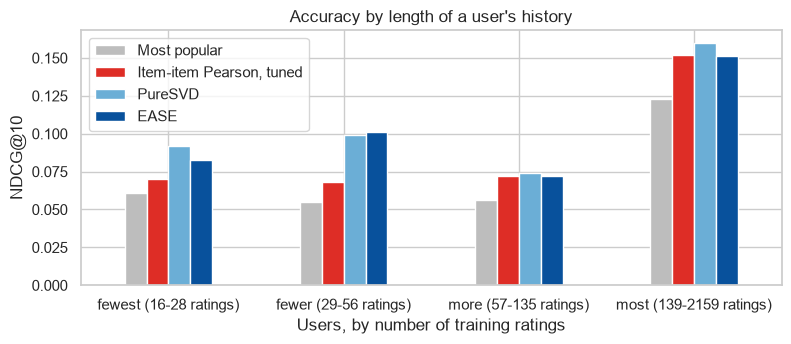

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
by_history.plot.bar(ax=ax, color=["#bdbdbd", "#de2d26", "#6baed6", "#08519c"], rot=0)
ax.set_ylabel("NDCG@10")
ax.set_xlabel("Users, by number of training ratings")
ax.set_title("Accuracy by length of a user's history")
plt.tight_layout()
plt.savefig("images/by_history.png", dpi=150)

Scores are higher for the heaviest users simply because they have more later movies to find. The comparison that matters is within each group: the linear models gain most over popularity for users with **fewer than about 60 ratings** (roughly +50% to +80%), and about +30% for users with longer histories.

## Summary

| Approach | Idea | Result |
|---|---|---|
| Most popular | Same list for everyone | A hard baseline; covers 1% of the catalogue |
| Item-item cosine | Movies watched by the same people | Ties popularity |
| Item-item Pearson | Movies whose ratings correlate | Below popularity as usually built; beats it only when restricted to blockbusters |
| PureSVD | Low-rank factorisation of the ratings matrix | Best |
| EASE | Closed-form linear item-to-item model | Close second, recommends slightly more of the catalogue |

Both of the strongest models train in seconds on this data. With tens of thousands of movies, EASE's item-by-item matrix becomes the constraint, and a factorisation model is the practical choice.

## Limits

- 610 users is small. Differences of a few thousandths in NDCG are within noise; the gaps between the groups of models are not.
- Splitting each user's history by time still lets a model learn from *other* users' later ratings. A single global cut-off date would be stricter.
- Only ratings are used. Genres, tags and release years could help most where the data is thinnest: new movies and new users.